In [1]:
# AI5707 - Assignment 7: GMM Models and Pattern Recognition
# Team digits: 1, 4, 6


In [2]:
import math
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42

# Manual Linear Congruential Generator used in Assignment 6
class ManualLCG:
    def __init__(self, seed=42):
        self.state = seed
        self.a = 1103515245
        self.c = 12345
        self.m = 2 ** 31

    def uniform(self):
        self.state = (self.a * self.state + self.c) % self.m
        return self.state / self.m

    def integer_below(self, limit):
        if limit <= 0:
            raise ValueError("Limit must be positive")

        # Rejection sampling avoids modulo bias
        threshold = self.m - (self.m % limit)
        while True:
            self.state = (self.a * self.state + self.c) % self.m
            if self.state < threshold:
                return self.state % limit

print("Manual LCG is used for random-number generation.")
print("Working directory:", Path.cwd())


Python random module is used for random-number generation.
Working directory: c:\Users\priya\Downloads\ML_Assignment_7


In [3]:
# STEP 1: Assignment 6 synthetic data settings

N = 1000
K = 3

weights1 = [0.40, 0.35, 0.25]
weights2 = [0.30, 0.40, 0.30]

means1 = [[-2, -3], [0, 0], [1, 4]]
means2 = [[6, -4], [7, 0], [8, 4]]

isotropic_cov1 = [
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 1.5]],
    [[1.2, 0.0], [0.0, 1.2]]
]
isotropic_cov2 = [
    [[1.2, 0.0], [0.0, 1.2]],
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 1.5]]
]

diagonal_cov1 = [
    [[2.0, 0.0], [0.0, 0.8]],
    [[0.8, 0.0], [0.0, 2.0]],
    [[1.5, 0.0], [0.0, 0.6]]
]
diagonal_cov2 = [
    [[1.0, 0.0], [0.0, 2.0]],
    [[2.0, 0.0], [0.0, 1.0]],
    [[1.5, 0.0], [0.0, 0.8]]
]

full_cov1 = [
    [[2.0, 0.8], [0.8, 1.5]],
    [[1.5, -0.6], [-0.6, 2.0]],
    [[2.0, 1.0], [1.0, 1.5]]
]
full_cov2 = [
    [[1.5, -0.7], [-0.7, 2.0]],
    [[2.0, 0.9], [0.9, 1.5]],
    [[1.5, -0.5], [-0.5, 1.0]]
]

print("Samples per class:", N)
print("Gaussian components per class:", K)
print("Class 1 weights:", weights1, "| means:", means1)
print("Class 2 weights:", weights2, "| means:", means2)


Samples per class: 1000
Gaussian components per class: 3
Class 1 weights: [0.4, 0.35, 0.25] | means: [[-2, -3], [0, 0], [1, 4]]
Class 2 weights: [0.3, 0.4, 0.3] | means: [[6, -4], [7, 0], [8, 4]]


In [4]:
# STEP 2: Generate standard normal values using Box-Muller

def box_muller(generator):
    u1 = generator.uniform()
    while u1 == 0:
        u1 = generator.uniform()
    u2 = generator.uniform()

    radius = math.sqrt(-2 * math.log(u1))
    angle = 2 * math.pi * u2
    return radius * math.cos(angle), radius * math.sin(angle)

# Reproducible test values using the manual LCG
z1, z2 = box_muller(ManualLCG(SEED))
print("Standard normal test values:", z1, z2)


Standard normal test values: 0.9340561449667306 0.14800466463450282


In [5]:
# STEP 3: Transform standard normal values using the covariance matrix

def transform_gaussian(z1, z2, mean, covariance):
    a = covariance[0][0]
    b = covariance[0][1]
    d = covariance[1][1]

    if covariance[1][0] != b:
        raise ValueError("Covariance matrix must be symmetric")
    if a <= 0 or a * d - b * b <= 0:
        raise ValueError("Covariance matrix must be positive definite")

    l11 = math.sqrt(a)
    l21 = b / l11
    l22 = math.sqrt(d - l21 * l21)

    x1 = mean[0] + l11 * z1
    x2 = mean[1] + l21 * z1 + l22 * z2
    return [x1, x2]

z1, z2 = box_muller(ManualLCG(SEED + 1))
print("Gaussian transformation test:", transform_gaussian(z1, z2, means1[0], full_cov1[0]))


Gaussian transformation test: [-1.619319665939214, -1.1269810106395717]


In [6]:
# STEP 4: Select a component and generate the Assignment 6 data

def select_component(weights, generator):
    value = generator.uniform()
    cumulative = 0.0
    for index, weight in enumerate(weights):
        cumulative += weight
        if value < cumulative:
            return index
    return len(weights) - 1

# Reproducible component-selection tests
print("Component-selection tests:",
      select_component(weights1, ManualLCG(SEED + 2)),
      select_component(weights2, ManualLCG(SEED + 3)))

def generate_gmm_data(n, weights, means, covariances, generator):
    data = []
    component_labels = []
    for _ in range(n):
        component = select_component(weights, generator)
        z1, z2 = box_muller(generator)
        point = transform_gaussian(z1, z2, means[component], covariances[component])
        data.append(point)
        component_labels.append(component)
    return data, component_labels

# Match the independent generator streams used in the revised Assignment 6
iso_data1, iso_labels1 = generate_gmm_data(N, weights1, means1, isotropic_cov1, ManualLCG(SEED + 1))
iso_data2, iso_labels2 = generate_gmm_data(N, weights2, means2, isotropic_cov2, ManualLCG(SEED + 2))
diag_data1, diag_labels1 = generate_gmm_data(N, weights1, means1, diagonal_cov1, ManualLCG(SEED + 101))
diag_data2, diag_labels2 = generate_gmm_data(N, weights2, means2, diagonal_cov2, ManualLCG(SEED + 102))
full_data1, full_labels1 = generate_gmm_data(N, weights1, means1, full_cov1, ManualLCG(SEED + 201))
full_data2, full_labels2 = generate_gmm_data(N, weights2, means2, full_cov2, ManualLCG(SEED + 202))

print("Assignment 6 synthetic samples regenerated using ManualLCG.")
print("Isotropic:", len(iso_data1), len(iso_data2))
print("Diagonal:", len(diag_data1), len(diag_data2))
print("Full covariance:", len(full_data1), len(full_data2))


Component-selection tests: 1 1
Assignment 6 synthetic samples regenerated.
Isotropic: 1000 1000
Diagonal: 1000 1000
Full covariance: 1000 1000


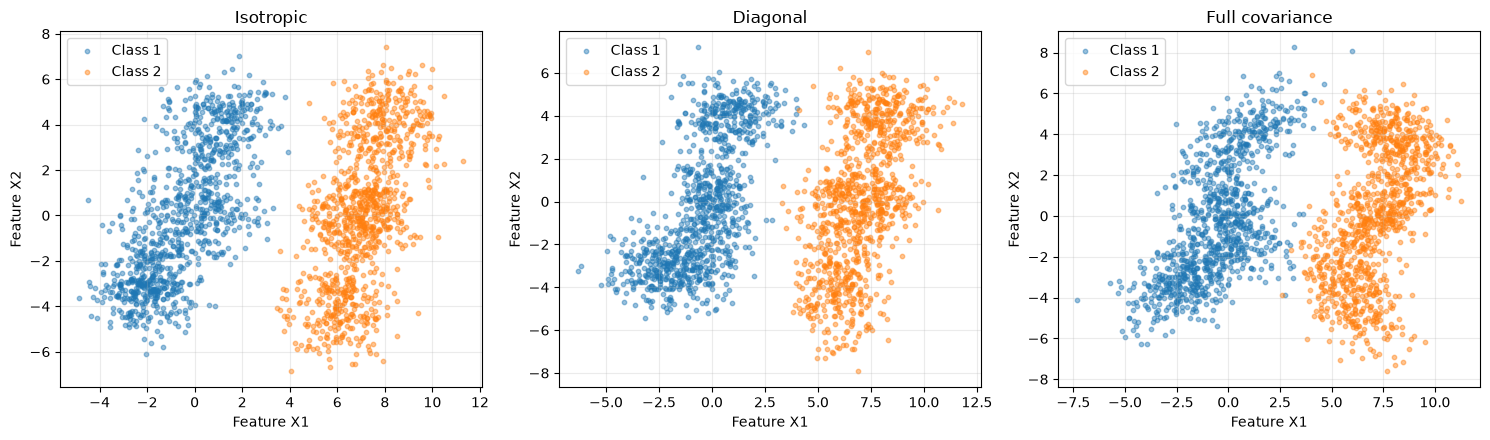

In [7]:
# STEP 5: Visualize the synthetic data

datasets = [
    ("Isotropic", iso_data1, iso_data2),
    ("Diagonal", diag_data1, diag_data2),
    ("Full covariance", full_data1, full_data2)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, class1, class2) in zip(axes, datasets):
    ax.scatter([p[0] for p in class1], [p[1] for p in class1], s=10, alpha=0.45, label="Class 1")
    ax.scatter([p[0] for p in class2], [p[1] for p in class2], s=10, alpha=0.45, label="Class 2")
    ax.set_title(title)
    ax.set_xlabel("Feature X1")
    ax.set_ylabel("Feature X2")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [8]:
# STEP 6: Split the exact generated samples into 80% training and 20% testing

def train_test_split_manual(data, generator, train_ratio=0.8):
    shuffled_data = data.copy()

    # Manual Fisher-Yates shuffle using the Assignment 6 LCG
    for i in range(len(shuffled_data) - 1, 0, -1):
        j = generator.integer_below(i + 1)
        shuffled_data[i], shuffled_data[j] = shuffled_data[j], shuffled_data[i]

    train_size = int(len(shuffled_data) * train_ratio)
    return shuffled_data[:train_size], shuffled_data[train_size:]

iso_train1, iso_test1 = train_test_split_manual(iso_data1, ManualLCG(5001))
iso_train2, iso_test2 = train_test_split_manual(iso_data2, ManualLCG(5002))
diag_train1, diag_test1 = train_test_split_manual(diag_data1, ManualLCG(5101))
diag_train2, diag_test2 = train_test_split_manual(diag_data2, ManualLCG(5102))
full_train1, full_test1 = train_test_split_manual(full_data1, ManualLCG(5201))
full_train2, full_test2 = train_test_split_manual(full_data2, ManualLCG(5202))

print("Isotropic:", len(iso_train1), "train /", len(iso_test1), "test per class")
print("Diagonal:", len(diag_train1), "train /", len(diag_test1), "test per class")
print("Full covariance:", len(full_train1), "train /", len(full_test1), "test per class")


Isotropic: 800 train / 200 test per class
Diagonal: 800 train / 200 test per class
Full covariance: 800 train / 200 test per class


In [9]:
# STEP 7: GMM implementation using Python lists and math only

class GaussianMixtureModel:
    def __init__(self, n_components=3, covariance_type="full",
                 max_iterations=40, tolerance=1e-4, reg_covar=1e-4, seed=42):
        if covariance_type not in ("isotropic", "diagonal", "full"):
            raise ValueError("Unknown covariance type")
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.max_iterations = max_iterations
        self.tolerance = tolerance
        self.reg_covar = reg_covar
        self.rng = ManualLCG(seed)
        self.weights = []
        self.means = []
        self.covariances = []
        self.log_likelihood_history = []

    def _covariance_for_component(self, samples, responsibilities, mean, component):
        dimension = len(mean)
        total = sum(responsibilities)
        variances = []
        for j in range(dimension):
            variances.append(
                sum(responsibilities[i] * (samples[i][j] - mean[j]) ** 2
                    for i in range(len(samples))) / max(total, 1e-12)
            )

        if self.covariance_type == "isotropic":
            variance = max(sum(variances) / dimension, self.reg_covar)
            return [variance] * dimension
        if self.covariance_type == "diagonal" or dimension != 2:
            return [max(value, self.reg_covar) for value in variances]

        var_x = variances[0]
        var_y = variances[1]
        covariance_xy = (
            sum(responsibilities[i] * (samples[i][0] - mean[0]) *
                (samples[i][1] - mean[1]) for i in range(len(samples)))
            / max(total, 1e-12)
        )
        var_x = max(var_x, self.reg_covar)
        var_y = max(var_y, self.reg_covar)
        limit = math.sqrt(var_x * var_y) * 0.999
        covariance_xy = max(-limit, min(limit, covariance_xy))
        return [[var_x, covariance_xy], [covariance_xy, var_y]]

    def _log_gaussian(self, sample, mean, covariance):
        dimension = len(sample)
        if self.covariance_type == "full" and dimension == 2 and isinstance(covariance[0], list):
            a, b = covariance[0]
            _, d = covariance[1]
            determinant = max(a * d - b * b, self.reg_covar ** 2)
            dx = sample[0] - mean[0]
            dy = sample[1] - mean[1]
            mahalanobis = (d * dx * dx - 2 * b * dx * dy + a * dy * dy) / determinant
            return -0.5 * (dimension * math.log(2 * math.pi) + math.log(determinant) + mahalanobis)

        log_det = sum(math.log(max(value, self.reg_covar)) for value in covariance)
        mahalanobis = sum((sample[j] - mean[j]) ** 2 / max(covariance[j], self.reg_covar)
                          for j in range(dimension))
        return -0.5 * (dimension * math.log(2 * math.pi) + log_det + mahalanobis)

    @staticmethod
    def _log_sum_exp(values):
        maximum = max(values)
        return maximum + math.log(sum(math.exp(value - maximum) for value in values) + 1e-300)

    def _component_log_scores(self, sample):
        scores = []
        for k in range(self.n_components):
            scores.append(math.log(max(self.weights[k], 1e-300)) +
                          self._log_gaussian(sample, self.means[k], self.covariances[k]))
        return scores

    def fit(self, samples):
        samples = [list(map(float, sample)) for sample in samples]
        n = len(samples)
        dimension = len(samples[0])
        if n < self.n_components:
            raise ValueError("Not enough training samples")

        available_indices = list(range(n))
        selected_indices = []
        for _ in range(self.n_components):
            selected_position = self.rng.integer_below(len(available_indices))
            selected_indices.append(available_indices.pop(selected_position))
        self.means = [samples[index][:] for index in selected_indices]

        global_variances = []
        for j in range(dimension):
            column = [sample[j] for sample in samples]
            average = sum(column) / n
            variance = sum((value - average) ** 2 for value in column) / n
            global_variances.append(max(variance, self.reg_covar))

        if self.covariance_type == "isotropic":
            average_variance = max(sum(global_variances) / dimension, self.reg_covar)
            initial_covariance = [average_variance] * dimension
        elif self.covariance_type == "full" and dimension == 2:
            initial_covariance = [[global_variances[0], 0.0], [0.0, global_variances[1]]]
        else:
            initial_covariance = global_variances[:]

        self.covariances = [
            ([row[:] for row in initial_covariance] if initial_covariance and isinstance(initial_covariance[0], list)
             else initial_covariance[:])
            for _ in range(self.n_components)
        ]
        self.weights = [1.0 / self.n_components] * self.n_components
        self.log_likelihood_history = []
        previous_likelihood = None

        for iteration in range(self.max_iterations):
            responsibilities = []
            likelihood = 0.0

            for sample in samples:
                log_scores = self._component_log_scores(sample)
                log_total = self._log_sum_exp(log_scores)
                likelihood += log_total
                responsibilities.append([math.exp(score - log_total) for score in log_scores])

            self.log_likelihood_history.append(likelihood)
            effective_counts = [
                sum(responsibilities[i][k] for i in range(n))
                for k in range(self.n_components)
            ]

            for k in range(self.n_components):
                count = max(effective_counts[k], 1e-10)
                self.weights[k] = count / n
                new_mean = []
                for j in range(dimension):
                    new_mean.append(
                        sum(responsibilities[i][k] * samples[i][j] for i in range(n)) / count
                    )
                self.means[k] = new_mean
                self.covariances[k] = self._covariance_for_component(
                    samples, [responsibilities[i][k] for i in range(n)], new_mean, k
                )

            if previous_likelihood is not None and abs(likelihood - previous_likelihood) <= (
                self.tolerance * (1 + abs(previous_likelihood))
            ):
                break
            previous_likelihood = likelihood

        return self

    def score_samples(self, samples):
        scores = []
        for sample in samples:
            scores.append(self._log_sum_exp(self._component_log_scores(sample)))
        return scores


In [10]:
# STEP 8: Class-wise GMM classifier and evaluation functions

class ClasswiseGMMClassifier:
    def __init__(self, n_components=3, covariance_type="full",
                 max_iterations=40, tolerance=1e-4, reg_covar=1e-4, seed=42):
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.max_iterations = max_iterations
        self.tolerance = tolerance
        self.reg_covar = reg_covar
        self.seed = seed
        self.models = {}
        self.priors = {}
        self.classes = []

    def fit(self, X, y):
        self.classes = sorted(set(y))
        for class_index, label in enumerate(self.classes):
            class_samples = [X[i] for i in range(len(X)) if y[i] == label]
            model = GaussianMixtureModel(
                n_components=self.n_components,
                covariance_type=self.covariance_type,
                max_iterations=self.max_iterations,
                tolerance=self.tolerance,
                reg_covar=self.reg_covar,
                seed=self.seed + class_index
            )
            model.fit(class_samples)
            self.models[label] = model
            self.priors[label] = len(class_samples) / len(X)
        return self

    def predict_log_scores(self, X):
        all_scores = []
        for sample in X:
            row = []
            for label in self.classes:
                row.append(self.models[label]._log_sum_exp(
                    self.models[label]._component_log_scores(sample)
                ) + math.log(max(self.priors[label], 1e-300)))
            all_scores.append(row)
        return all_scores

    def predict(self, X):
        predictions = []
        for row in self.predict_log_scores(X):
            best_index = max(range(len(row)), key=lambda index: row[index])
            predictions.append(self.classes[best_index])
        return predictions


def confusion_matrix_manual(y_true, y_pred, labels):
    matrix = [[0 for _ in labels] for _ in labels]
    index = {label: i for i, label in enumerate(labels)}
    for actual, predicted in zip(y_true, y_pred):
        matrix[index[actual]][index[predicted]] += 1
    return matrix


def plot_confusion_matrix(matrix, labels, title):
    fig, ax = plt.subplots(figsize=(5, 4))
    image = ax.imshow(matrix, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_xticks(range(len(labels)), labels=labels)
    ax.set_yticks(range(len(labels)), labels=labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(matrix[i][j]), ha="center", va="center")
    fig.colorbar(image, ax=ax)
    plt.tight_layout()
    plt.show()



 Isotropic GMM
Test accuracy: 100.00%
Confusion matrix (rows=true [1, 2], columns=predicted [1, 2]):
[200, 0]
[0, 200]


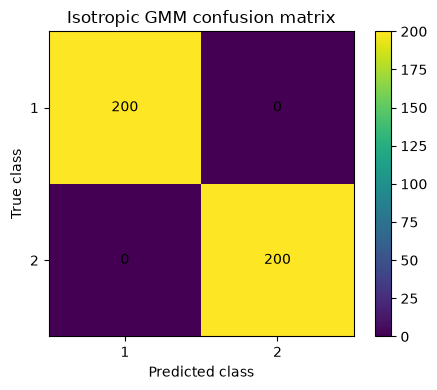


 Diagonal GMM
Test accuracy: 99.75%
Confusion matrix (rows=true [1, 2], columns=predicted [1, 2]):
[200, 0]
[1, 199]


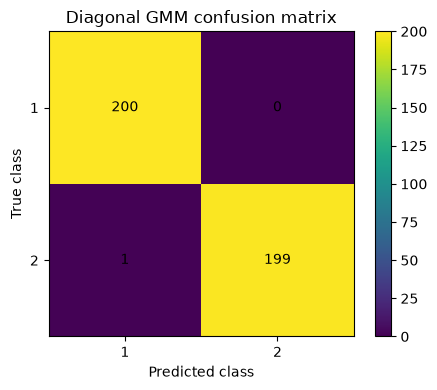


 Full covariance GMM
Test accuracy: 99.75%
Confusion matrix (rows=true [1, 2], columns=predicted [1, 2]):
[200, 0]
[1, 199]


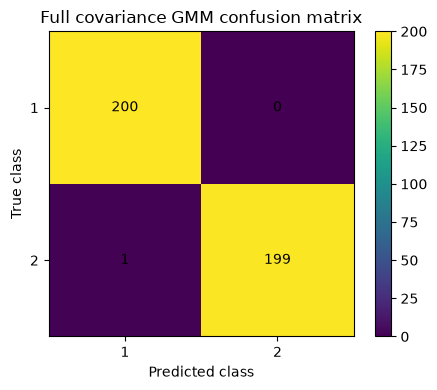

In [11]:
# STEP 9: Train and test GMMs on Assignment 6 data

synthetic_sets = {
    "Isotropic": (iso_train1, iso_test1, iso_train2, iso_test2, "isotropic"),
    "Diagonal": (diag_train1, diag_test1, diag_train2, diag_test2, "diagonal"),
    "Full covariance": (full_train1, full_test1, full_train2, full_test2, "full")
}
synthetic_results = {}

for name, (train1, test1, train2, test2, covariance_type) in synthetic_sets.items():
    X_train = train1 + train2
    y_train = [1] * len(train1) + [2] * len(train2)
    X_test = test1 + test2
    y_test = [1] * len(test1) + [2] * len(test2)

    classifier = ClasswiseGMMClassifier(
        n_components=3, covariance_type=covariance_type,
        max_iterations=50, tolerance=1e-4, reg_covar=1e-5, seed=SEED
    )
    classifier.fit(X_train, y_train)
    predictions = classifier.predict(X_test)
    matrix = confusion_matrix_manual(y_test, predictions, [1, 2])
    accuracy = 100.0 * sum(a == b for a, b in zip(y_test, predictions)) / len(y_test)

    synthetic_results[name] = {
        "classifier": classifier, "X_train": X_train, "y_train": y_train,
        "X_test": X_test, "y_test": y_test, "predictions": predictions,
        "matrix": matrix, "accuracy": accuracy
    }

    print("\n", name, "GMM")
    print("Test accuracy: %.2f%%" % accuracy)
    print("Confusion matrix (rows=true [1, 2], columns=predicted [1, 2]):")
    for row in matrix:
        print(row)
    plot_confusion_matrix(matrix, [1, 2], name + " GMM confusion matrix")


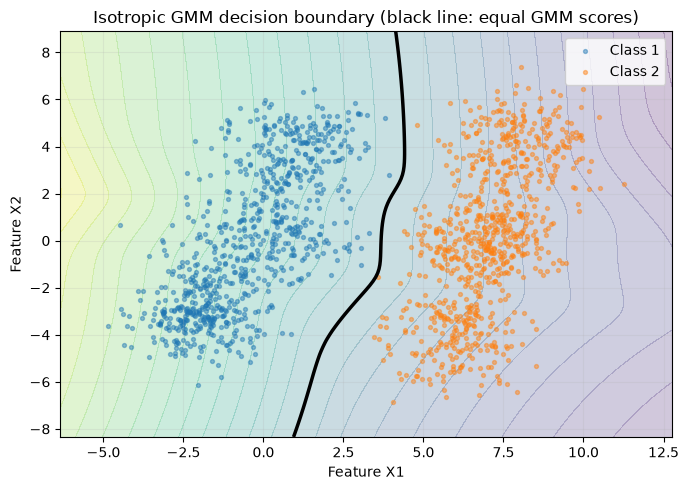

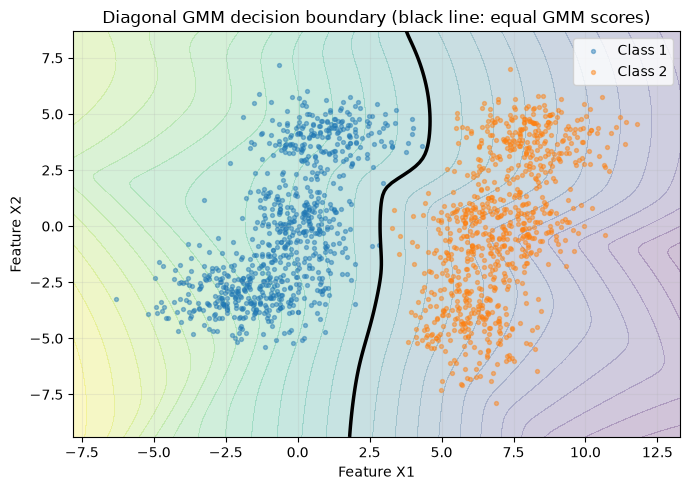

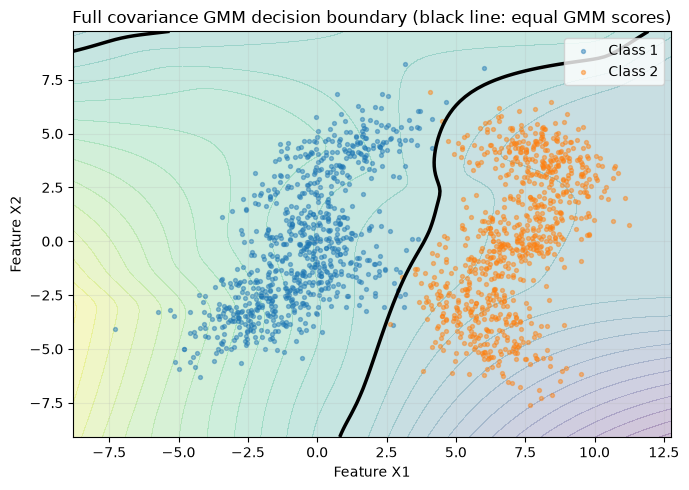

In [12]:
# STEP 10: Plot GMM decision boundaries for the synthetic data

def plot_decision_boundary(result, title, grid_size=100):
    X_train = result["X_train"]
    classifier = result["classifier"]
    x_values = [point[0] for point in X_train]
    y_values = [point[1] for point in X_train]
    x_min, x_max = min(x_values) - 1.5, max(x_values) + 1.5
    y_min, y_max = min(y_values) - 1.5, max(y_values) + 1.5
    x_grid = [x_min + (x_max - x_min) * i / (grid_size - 1)
              for i in range(grid_size)]
    y_grid = [y_min + (y_max - y_min) * i / (grid_size - 1)
              for i in range(grid_size)]

    score_difference = []
    for y_value in y_grid:
        row = []
        for x_value in x_grid:
            scores = classifier.predict_log_scores([[x_value, y_value]])[0]
            row.append(scores[0] - scores[1])
        score_difference.append(row)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.contourf(x_grid, y_grid, score_difference, levels=25, alpha=0.25)
    ax.contour(x_grid, y_grid, score_difference, levels=[0],
               colors="black", linewidths=2.5)

    ax.scatter([p[0] for p, label in zip(X_train, result["y_train"]) if label == 1],
               [p[1] for p, label in zip(X_train, result["y_train"]) if label == 1],
               s=8, alpha=0.45, label="Class 1")
    ax.scatter([p[0] for p, label in zip(X_train, result["y_train"]) if label == 2],
               [p[1] for p, label in zip(X_train, result["y_train"]) if label == 2],
               s=8, alpha=0.45, label="Class 2")
    ax.set_title(title + " (black line: equal GMM scores)")
    ax.set_xlabel("Feature X1")
    ax.set_ylabel("Feature X2")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

for name, result in synthetic_results.items():
    plot_decision_boundary(result, name + " GMM decision boundary")


In [13]:
# STEP 11: Load TEAM_19 digit images and use 2x2 average pooling

def locate_dataset():
    root = Path.cwd()
    if (root / "TEAM_19").is_dir():
        return root / "TEAM_19"
    for zip_name in ("TEAM_19(1).zip", "TEAM_19.zip"):
        zip_path = root / zip_name
        if zip_path.is_file():
            with zipfile.ZipFile(zip_path, "r") as archive:
                archive.extractall(root)
            if (root / "TEAM_19").is_dir():
                return root / "TEAM_19"
    raise FileNotFoundError(
        "Place the extracted TEAM_19 folder or TEAM_19(1).zip beside this notebook."
    )


class DigitImageDataset:
    def __init__(self, root_dir, digits=(1, 4, 6), pooling_block=2):
        self.root_dir = Path(root_dir)
        self.digits = tuple(digits)
        self.pooling_block = pooling_block

    def image_to_features(self, image_path):
        image = Image.open(image_path).convert("L")
        if image.size != (28, 28):
            raise ValueError("Expected 28x28 image: " + str(image_path))
        pixels = list(image.getdata())
        block = self.pooling_block
        reduced = []
        for block_row in range(28 // block):
            for block_col in range(28 // block):
                values = []
                for row in range(block_row * block, (block_row + 1) * block):
                    for col in range(block_col * block, (block_col + 1) * block):
                        values.append(pixels[row * 28 + col] / 255.0)
                reduced.append(sum(values) / len(values))
        return reduced

    def load_split(self, split_name):
        X, y = [], []
        split_dir = self.root_dir / split_name
        if not split_dir.is_dir():
            raise FileNotFoundError("Missing split folder: " + str(split_dir))
        extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
        for digit in self.digits:
            digit_dir = split_dir / str(digit)
            if not digit_dir.is_dir():
                raise FileNotFoundError("Missing digit folder: " + str(digit_dir))
            for image_path in sorted(digit_dir.rglob("*")):
                if image_path.is_file() and image_path.suffix.lower() in extensions:
                    X.append(self.image_to_features(image_path))
                    y.append(digit)
        return X, y


dataset_root = locate_dataset()
digit_dataset = DigitImageDataset(dataset_root, digits=(1, 4, 6), pooling_block=2)
X_digit_train, y_digit_train = digit_dataset.load_split("train")
X_digit_dev, y_digit_dev = digit_dataset.load_split("dev")
X_digit_test, y_digit_test = digit_dataset.load_split("test")

print("Dataset:", dataset_root.resolve())
print("Training images:", len(X_digit_train), "| features per image:", len(X_digit_train[0]))
print("Development images:", len(X_digit_dev))
print("Test images:", len(X_digit_test))
print("Training class counts:", {d: y_digit_train.count(d) for d in (1, 4, 6)})
print("Test class counts:", {d: y_digit_test.count(d) for d in (1, 4, 6)})


C:\Users\priya\AppData\Local\Temp\ipykernel_28988\1743772951.py:29: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(image.getdata())


Dataset: C:\Users\priya\Downloads\ML_Assignment_7\TEAM_19
Training images: 14816 | features per image: 196
Development images: 3686
Test images: 3075
Training class counts: {1: 5383, 4: 4681, 6: 4752}
Test class counts: {1: 1135, 4: 982, 6: 958}


C:\Users\priya\AppData\Local\Temp\ipykernel_28988\1743772951.py:29: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(image.getdata())


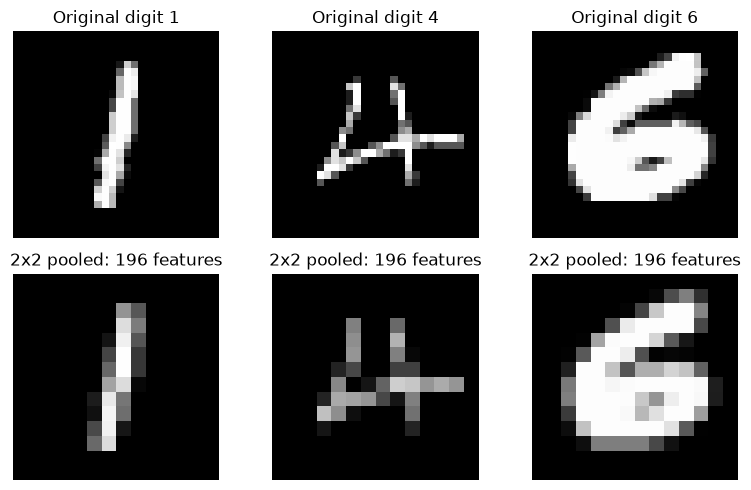

In [14]:
# STEP 12: Display original digit examples and their 2x2-pooled representation

fig, axes = plt.subplots(2, 3, figsize=(8, 5))
for column, digit in enumerate((1, 4, 6)):
    image_path = next((dataset_root / "train" / str(digit)).glob("*"))
    original = Image.open(image_path).convert("L")
    pooled = digit_dataset.image_to_features(image_path)
    axes[0][column].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0][column].set_title("Original digit " + str(digit))
    axes[0][column].axis("off")
    axes[1][column].imshow(
        [pooled[row * 14:(row + 1) * 14] for row in range(14)],
        cmap="gray", vmin=0, vmax=1, interpolation="nearest"
    )
    axes[1][column].set_title("2x2 pooled: 196 features")
    axes[1][column].axis("off")
plt.tight_layout()
plt.show()


In [15]:
# STEP 13: Train one GMM per digit using training images only
# Diagonal covariance and two components keep pure-Python training practical for 196 features.

digit_classifier = ClasswiseGMMClassifier(
    n_components=2,
    covariance_type="diagonal",
    max_iterations=8,
    tolerance=1e-4,
    reg_covar=1e-4,
    seed=SEED
)
digit_classifier.fit(X_digit_train, y_digit_train)

for digit in digit_classifier.classes:
    model = digit_classifier.models[digit]
    print("Digit", digit,
          "| training images:", y_digit_train.count(digit),
          "| EM iterations:", len(model.log_likelihood_history),
          "| final log likelihood:", round(model.log_likelihood_history[-1], 2))


Digit 1 | training images: 5383 | EM iterations: 8 | final log likelihood: 2569388.78
Digit 4 | training images: 4681 | EM iterations: 8 | final log likelihood: 1606781.47
Digit 6 | training images: 4752 | EM iterations: 8 | final log likelihood: 1742692.61


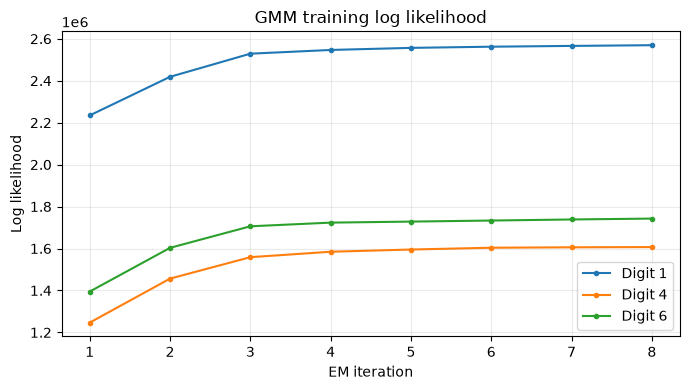

In [16]:
# STEP 14: Plot training log-likelihood values

fig, ax = plt.subplots(figsize=(7, 4))
for digit in digit_classifier.classes:
    history = digit_classifier.models[digit].log_likelihood_history
    ax.plot(list(range(1, len(history) + 1)), history, marker=".", label="Digit " + str(digit))
ax.set_title("GMM training log likelihood")
ax.set_xlabel("EM iteration")
ax.set_ylabel("Log likelihood")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Overall test accuracy: 96.88%
Correct predictions: 2979 / 3075
Digit 1 accuracy: 97.80% (1110/1135)
Digit 4 accuracy: 94.50% (928/982)
Digit 6 accuracy: 98.23% (941/958)
Confusion matrix (rows=true [1, 4, 6], columns=predicted [1, 4, 6]):
[1110, 9, 16]
[5, 928, 49]
[5, 12, 941]


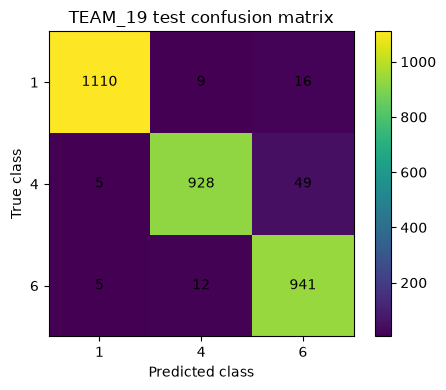

In [17]:
# STEP 15: Classify test images and record the results

y_digit_pred = digit_classifier.predict(X_digit_test)
digit_labels = [1, 4, 6]
digit_matrix = confusion_matrix_manual(y_digit_test, y_digit_pred, digit_labels)
digit_accuracy = 100.0 * sum(a == b for a, b in zip(y_digit_test, y_digit_pred)) / len(y_digit_test)

print("Overall test accuracy: %.2f%%" % digit_accuracy)
print("Correct predictions:", sum(a == b for a, b in zip(y_digit_test, y_digit_pred)), "/", len(y_digit_test))
for digit in digit_labels:
    indices = [i for i, label in enumerate(y_digit_test) if label == digit]
    correct = sum(y_digit_pred[i] == digit for i in indices)
    print("Digit", digit, "accuracy: %.2f%% (%d/%d)" %
          (100.0 * correct / len(indices), correct, len(indices)))

print("Confusion matrix (rows=true [1, 4, 6], columns=predicted [1, 4, 6]):")
for row in digit_matrix:
    print(row)
plot_confusion_matrix(digit_matrix, digit_labels, "TEAM_19 test confusion matrix")


Misclassification pairs: count, true digit, predicted digit
49 4 6
16 1 6
12 6 4
9 1 4
5 6 1
5 4 1
Mean score margin, correct predictions: 477.3663
Mean score margin, misclassified predictions: 134.6297


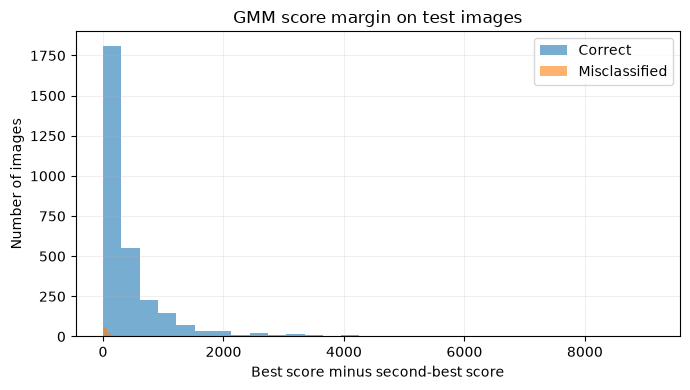

In [18]:
# STEP 16: Explain confusions using class-score differences and boundaries

confusion_pairs = []
for row_index, true_digit in enumerate(digit_labels):
    for column_index, predicted_digit in enumerate(digit_labels):
        if row_index != column_index and digit_matrix[row_index][column_index] > 0:
            confusion_pairs.append((digit_matrix[row_index][column_index], true_digit, predicted_digit))
confusion_pairs.sort(reverse=True)

print("Misclassification pairs: count, true digit, predicted digit")
for count, true_digit, predicted_digit in confusion_pairs:
    print(count, true_digit, predicted_digit)

score_rows = digit_classifier.predict_log_scores(X_digit_test)
margins = []
misclassified = []
for index, row in enumerate(score_rows):
    ordered = sorted(row)
    margin = ordered[-1] - ordered[-2]
    margins.append(margin)
    if y_digit_pred[index] != y_digit_test[index]:
        misclassified.append(index)

correct_margins = [margins[i] for i in range(len(margins)) if y_digit_pred[i] == y_digit_test[i]]
error_margins = [margins[i] for i in misclassified]
if correct_margins:
    print("Mean score margin, correct predictions:", round(sum(correct_margins) / len(correct_margins), 4))
if error_margins:
    print("Mean score margin, misclassified predictions:", round(sum(error_margins) / len(error_margins), 4))

fig, ax = plt.subplots(figsize=(7, 4))
if correct_margins:
    ax.hist(correct_margins, bins=30, alpha=0.6, label="Correct")
if error_margins:
    ax.hist(error_margins, bins=30, alpha=0.6, label="Misclassified")
ax.set_title("GMM score margin on test images")
ax.set_xlabel("Best score minus second-best score")
ax.set_ylabel("Number of images")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Boundary plot feature indices: 102 and 91
Other 194 features are fixed at their training-set means for each plot.


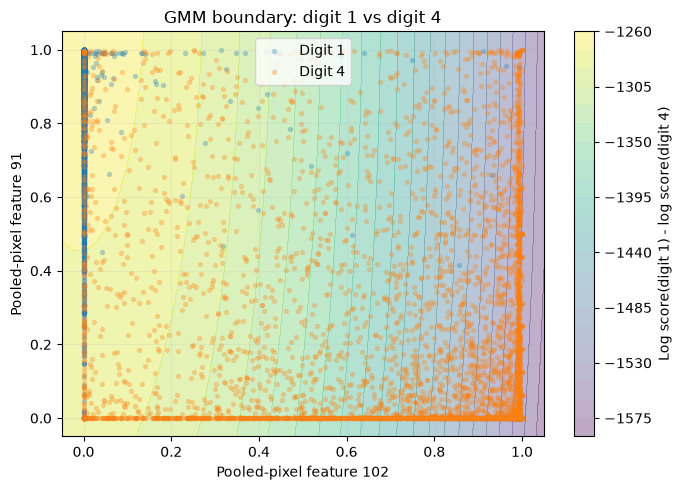

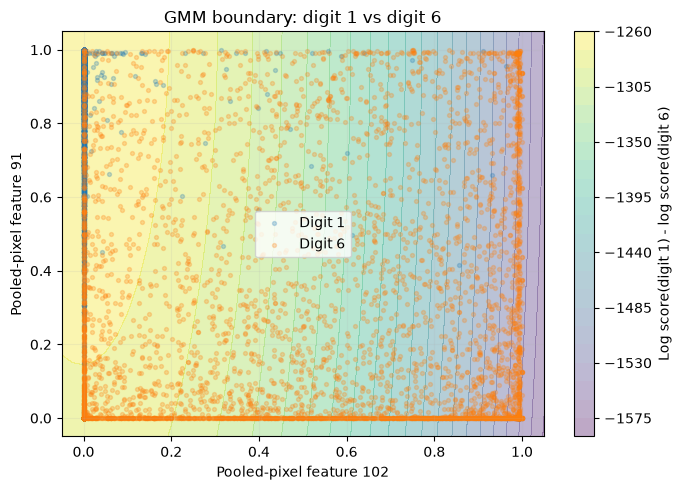

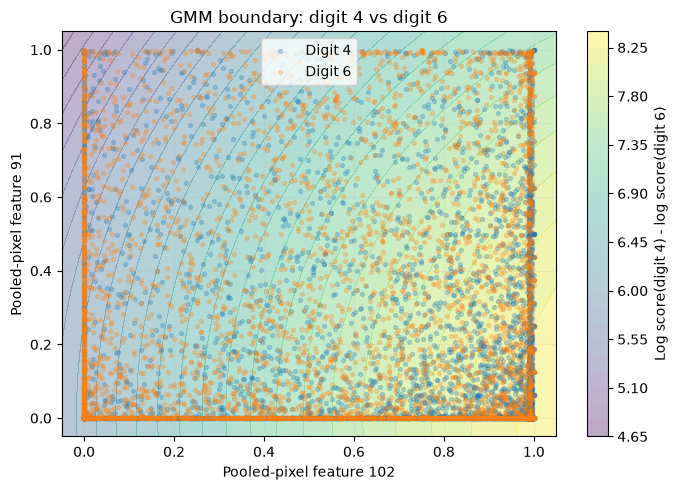

In [19]:
# STEP 17: Draw pairwise GMM decision-boundary lines for digits 1, 4, and 6
# Plot two pooled-pixel features at a time and hold the other features at their training means.

feature_count = len(X_digit_train[0])
feature_means = [
    sum(sample[j] for sample in X_digit_train) / len(X_digit_train)
    for j in range(feature_count)
]
feature_variances = [
    sum((sample[j] - feature_means[j]) ** 2 for sample in X_digit_train)
    / len(X_digit_train)
    for j in range(feature_count)
]
feature_indices = sorted(
    range(feature_count), key=lambda j: feature_variances[j], reverse=True
)[:2]
feature_x, feature_y = feature_indices

print("Boundary plot feature indices:", feature_x, "and", feature_y)
print("Other 194 features are fixed at their training-set means for each plot.")

def plot_digit_pair_boundary(classifier, X_train, y_train, digit_a, digit_b,
                             feature_x, feature_y, feature_means, grid_size=45):
    x_values = [sample[feature_x] for sample, label in zip(X_train, y_train)
                if label in (digit_a, digit_b)]
    y_values = [sample[feature_y] for sample, label in zip(X_train, y_train)
                if label in (digit_a, digit_b)]
    x_min, x_max = min(x_values) - 0.05, max(x_values) + 0.05
    y_min, y_max = min(y_values) - 0.05, max(y_values) + 0.05
    x_grid = [x_min + (x_max - x_min) * i / (grid_size - 1)
              for i in range(grid_size)]
    y_grid = [y_min + (y_max - y_min) * i / (grid_size - 1)
              for i in range(grid_size)]

    score_difference = []
    for y_value in y_grid:
        row = []
        for x_value in x_grid:
            sample = feature_means[:]
            sample[feature_x] = x_value
            sample[feature_y] = y_value
            scores = classifier.predict_log_scores([sample])[0]
            score_a = scores[classifier.classes.index(digit_a)]
            score_b = scores[classifier.classes.index(digit_b)]
            row.append(score_a - score_b)
        score_difference.append(row)

    fig, ax = plt.subplots(figsize=(7, 5))
    filled = ax.contourf(x_grid, y_grid, score_difference, levels=25, alpha=0.35)
    ax.contour(x_grid, y_grid, score_difference, levels=[0],
               colors="black", linewidths=2.5)
    fig.colorbar(filled, ax=ax, label="Log score(digit %d) - log score(digit %d)"
                 % (digit_a, digit_b))

    for digit in (digit_a, digit_b):
        points = [sample for sample, label in zip(X_train, y_train) if label == digit]
        ax.scatter([sample[feature_x] for sample in points],
                   [sample[feature_y] for sample in points],
                   s=8, alpha=0.25, label="Digit " + str(digit))

    ax.set_title("GMM boundary: digit %d vs digit %d" % (digit_a, digit_b))
    ax.set_xlabel("Pooled-pixel feature " + str(feature_x))
    ax.set_ylabel("Pooled-pixel feature " + str(feature_y))
    ax.legend()
    ax.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()

for digit_a, digit_b in ((1, 4), (1, 6), (4, 6)):
    plot_digit_pair_boundary(
        digit_classifier, X_digit_train, y_digit_train,
        digit_a, digit_b, feature_x, feature_y, feature_means
    )


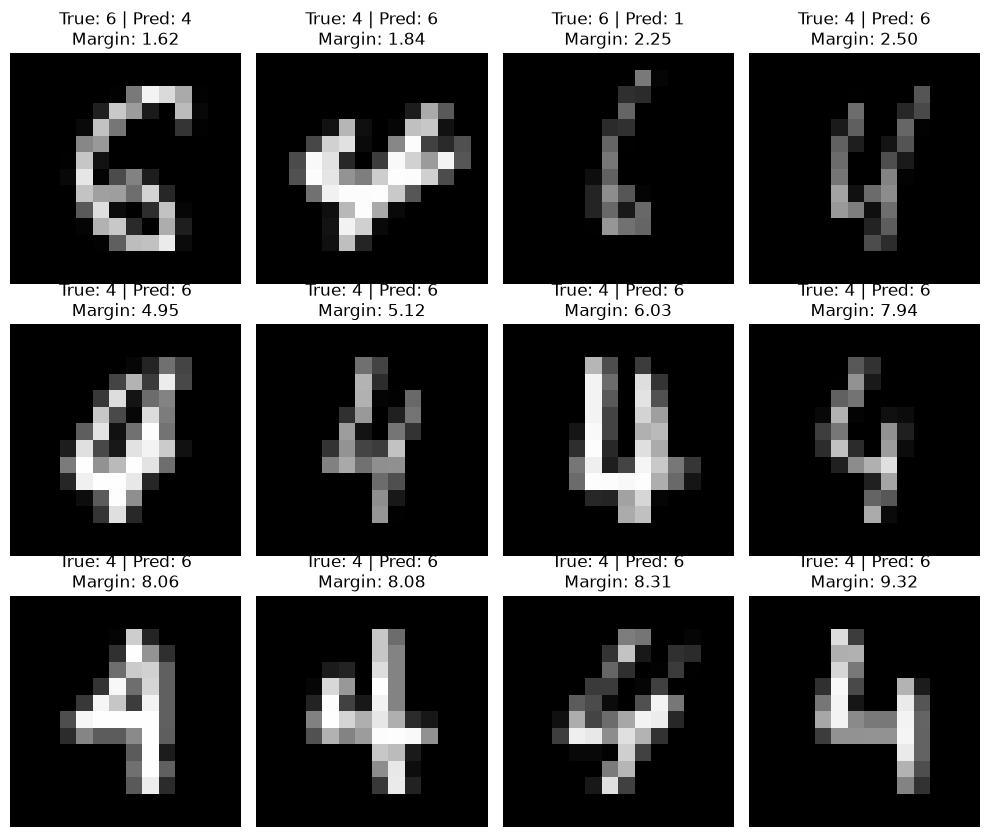

In [20]:
# STEP 18: Display misclassified examples nearest to a GMM decision boundary

if not misclassified:
    print("No test misclassifications were observed.")
else:
    selected = sorted(misclassified, key=lambda i: margins[i])[:12]
    columns = 4
    rows = (len(selected) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(10, 2.8 * rows))
    if rows == 1:
        axes = [axes]
    axes = [axes[r][col] for r in range(rows) for col in range(columns)]
    for ax, index in zip(axes, selected):
        pooled_image = [X_digit_test[index][row * 14:(row + 1) * 14] for row in range(14)]
        ax.imshow(pooled_image, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title("True: %d | Pred: %d\nMargin: %.2f" %
                     (y_digit_test[index], y_digit_pred[index], margins[index]))
        ax.axis("off")
    for ax in axes[len(selected):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [ ]:
# Report observations from the actual outputs:
# - Question 1: compare confusion matrices for the three covariance types.
# - Question 2: each digit GMM is trained only on the training split; 2x2 pooling gives 196 features.
# - Question 3: report overall and per-digit test accuracy and the test confusion matrix.
# - Question 4: use the most frequent confused pairs, score margins, and displayed examples to explain boundary overlap.

